In [1]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
#import xgb_utils
import numpy as np
import pandas as pd
import os
import uproot
import awkward as ak
import sys
import matplotlib.pyplot as plt
import mplhep as hep
import seaborn as sns

%matplotlib inline

In [2]:
plot_path = f"../../plots/xgboost/categorization/"

In [3]:
print("hi")

hi


In [4]:
!nvidia-smi

Thu Aug 27 19:57:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          On  |   00000000:07:00.0 Off |                   On |
| N/A   35C    P0             89W /  300W |                  N/A   |     N/A      Default |
|                                         |                        |              Enabled |
+-----------------------------------------+-----

In [5]:
def plot_confusion_matrix(y_true, y_pred, counts, labels=['ggH', 'VBF'], title=""):
    """
    Plot confusion matrix normalized by the true class (rows).
    Each row sums to 100%.
    """
    ggH_events = counts[0]
    VBF_events = counts[1]
    
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # Normalize each row
    cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    ggH_event_arr = np.array([[1,1],[0,0]])*ggH_events
    VBF_event_arr = np.array([[0,0],[1,1]])*VBF_events
    cm_event_arr = cm_percent/100*ggH_event_arr + cm_percent/100*VBF_event_arr

    #plt.figure(figsize=(8, 6))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(
        cm_percent,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=labels,
        yticklabels=labels,
        ax=axes[0],
    )
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    axes[0].set_title("Confusion Matrix (%) " + title)
    
    sns.heatmap(
        cm_event_arr,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=axes[1],
    )

    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("True")
    axes[1].set_title("Expected Events " + title)

    plt.tight_layout()
    plt.show()

In [6]:
bdt_variables = [
    "diJet_mass",
    "pt_balance",
    "pt_centrality",
    "leading_jet_eta",
    "subleading_jet_eta",
    "delta_eta_diJet",
    "delta_phi_diJet",
    "n_jet",
    "leading_jet_pt",
    "subleading_jet_pt",
    "min_delta_eta_diMuon_jet",
    "min_delta_phi_diMuon_jet",
    "diMuon_bsConstrainedPt",
    "diMuon_rapidity",
    "HT",
    "HT_pt2",
    "HT_pt5",
    "HT_pt10",
    "z_zeppenfeld",
    "is_ggH_category",
    "is_VBF_category",
    "weight",
]

bdt_variables1 = [
    "leading_jet_eta",
    "n_jet",
    "leading_jet_pt",
    "min_delta_eta_diMuon_jet",
    "min_delta_phi_diMuon_jet",
    "diMuon_bsConstrainedPt",
    "diMuon_rapidity",
    "HT",
    "HT_pt2",
    "HT_pt5",
    "HT_pt10",
    "is_ggH_category",
    "is_VBF_category",
    "weight",
]

bdt_variables0 = [
    "pt_balance",
    "pt_centrality",
    "n_jet",
    "diMuon_bsConstrainedPt",
    "mu1_bsConstrainedPt_mass_ratio",
    "mu2_bsConstrainedPt_mass_ratio",
    "diMuon_rapidity",
    "mu1_eta",
    "mu2_eta",
    "phi_CS",
    "cos_theta_CS",
    "z_zeppenfeld",
    "is_ggH_category",
    "is_VBF_category",
    "weight",
    "HT",
]

ggH_file_name= f"../../root_io/tuples/ggH_Combined_tuples.root"
VBF_file_name= f"../../root_io/tuples/VBF_Combined_tuples.root"
with uproot.open(ggH_file_name) as file:
    ggH = file["tree_output"].arrays(bdt_variables)
with uproot.open(VBF_file_name) as file:
    VBF = file["tree_output"].arrays(bdt_variables)

ggH_df = ak.to_dataframe(ggH).reset_index(drop=True)
VBF_df = ak.to_dataframe(VBF).reset_index(drop=True)

In [7]:
print(len(VBF_df))
print(len(ggH_df))

5417025
2705516


In [8]:
VBF_df[VBF_df.diJet_mass > 0]

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,...,diMuon_bsConstrainedPt,diMuon_rapidity,HT,HT_pt2,HT_pt5,HT_pt10,z_zeppenfeld,is_ggH_category,is_VBF_category,weight
2,773.0000,0.059998,0.257324,1.955566,-1.760986,3.716797,-2.335449,2,220.750000,63.546875,...,159.187500,0.477234,271.687500,264.06250,259.375000,259.375000,0.100891,0,1,0.000018
4,151.0625,0.047356,0.295105,-3.265137,-0.782959,2.482422,-2.470215,2,54.484375,30.398438,...,41.671875,-0.005829,151.031250,145.87500,145.875000,145.875000,0.811157,1,0,0.000016
5,226.1250,0.043190,0.325012,1.542969,-0.168823,1.711914,-2.235352,2,96.671875,75.015625,...,88.250000,-0.405334,203.250000,196.25000,193.968750,188.750000,-0.640137,1,0,0.000014
6,258.4375,0.120712,1.805176,0.053413,2.763672,2.710449,0.576172,2,87.734375,55.843750,...,162.093750,0.183777,266.000000,260.06250,248.531250,235.218750,-0.451355,1,0,0.000010
8,487.3750,0.326172,0.281677,1.096191,0.920166,0.176025,-3.018555,4,264.937500,221.156250,...,163.593750,0.670288,707.250000,686.12500,679.375000,662.375000,-1.875000,1,0,0.000010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5417020,1529.0000,0.030697,0.286194,-2.205566,4.110352,6.316406,-2.828613,2,105.375000,39.937500,...,75.078125,0.463013,188.937500,173.87500,127.953125,127.953125,-0.078461,0,1,0.000050
5417021,742.3750,0.074295,1.084229,-1.927734,2.539062,4.466797,1.061035,2,85.062500,75.203125,...,159.125000,-0.294861,238.625000,231.37500,221.406250,221.406250,-0.135223,0,1,0.000036
5417022,1241.2500,0.033943,2.008789,-1.686279,4.093750,5.780273,0.408325,3,83.546875,57.257812,...,141.656250,1.432373,262.625000,252.25000,226.500000,226.500000,0.039612,0,1,0.000028
5417023,569.1250,0.096817,0.062027,-0.529663,1.427246,1.957031,-3.107910,2,272.437500,128.687500,...,97.984375,1.132324,329.625000,320.56250,318.437500,318.437500,0.351318,1,0,0.000029


In [9]:
ggH_events = ggH_df[ggH_df.n_jet >= 0].weight.sum()
VBF_events = VBF_df[VBF_df.n_jet >= 0].weight.sum()

print("ggH events: " + str(ggH_events))
print("VBF events: " + str(VBF_events))

ggH events: 1850.7692471855848
VBF events: 144.40453519788701


In [10]:
ggH_df["y_truth"] = 0
VBF_df["y_truth"] = 1

In [11]:
print(len(VBF_df[VBF_df.n_jet == 1]))
print(len(ggH_df[ggH_df.n_jet == 1]))

2073168
805489


In [12]:
bdt_variables[:-3]

['diJet_mass',
 'pt_balance',
 'pt_centrality',
 'leading_jet_eta',
 'subleading_jet_eta',
 'delta_eta_diJet',
 'delta_phi_diJet',
 'n_jet',
 'leading_jet_pt',
 'subleading_jet_pt',
 'min_delta_eta_diMuon_jet',
 'min_delta_phi_diMuon_jet',
 'diMuon_bsConstrainedPt',
 'diMuon_rapidity',
 'HT',
 'HT_pt2',
 'HT_pt5',
 'HT_pt10',
 'z_zeppenfeld']

In [13]:
bdt_df = pd.concat(
    [ggH_df, VBF_df],
    ignore_index=True,
)

neither = (
    (bdt_df["is_ggH_category"] == 0) & 
    (bdt_df["is_VBF_category"] == 0)
)
bdt_df = bdt_df[~neither]
#bdt_df = bdt_df[bdt_df.n_jet == 1]

In [ ]:
bdt_df.insert(loc=len(bdt_variables[:-3]), column="HT_extra", value=(bdt_df.HT - bdt_df.leading_jet_pt).values)

In [14]:
bdt_df

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,...,diMuon_rapidity,HT,HT_pt2,HT_pt5,HT_pt10,z_zeppenfeld,is_ggH_category,is_VBF_category,weight,y_truth
0,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.000000,...,0.524170,193.875000,177.09375,140.000000,132.062500,0.000000,1,0,0.000303,0
1,0.000000,-1.000000,-1.000000,-0.860229,0.000000,0.000000,-1.000000,1,37.898438,0.000000,...,1.427490,181.656250,174.50000,156.906250,149.750000,0.000000,1,0,0.000697,0
2,62.906250,0.317627,0.768677,-0.946167,-2.197754,1.251709,1.260742,2,40.039062,29.316406,...,0.877441,170.875000,160.53125,129.625000,121.625000,1.965820,1,0,0.000575,0
3,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.000000,...,-1.793945,132.031250,127.93750,127.937500,127.937500,0.000000,1,0,0.000451,0
4,99.546875,0.281677,-0.113708,0.875488,-0.904175,1.779785,-2.291992,2,40.367188,32.382812,...,-0.729858,197.750000,178.87500,161.093750,148.250000,-0.408936,1,0,0.000720,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8122536,1529.000000,0.030697,0.286194,-2.205566,4.110352,6.316406,-2.828613,2,105.375000,39.937500,...,0.463013,188.937500,173.87500,127.953125,127.953125,-0.078461,0,1,0.000050,1
8122537,742.375000,0.074295,1.084229,-1.927734,2.539062,4.466797,1.061035,2,85.062500,75.203125,...,-0.294861,238.625000,231.37500,221.406250,221.406250,-0.135223,0,1,0.000036,1
8122538,1241.250000,0.033943,2.008789,-1.686279,4.093750,5.780273,0.408325,3,83.546875,57.257812,...,1.432373,262.625000,252.25000,226.500000,226.500000,0.039612,0,1,0.000028,1
8122539,569.125000,0.096817,0.062027,-0.529663,1.427246,1.957031,-3.107910,2,272.437500,128.687500,...,1.132324,329.625000,320.56250,318.437500,318.437500,0.351318,1,0,0.000029,1


In [ ]:
bdt_variables.insert(-3,"HT_extra")
bdt_variables

In [15]:
X = bdt_df[bdt_variables[:-3]]
Y = bdt_df["y_truth"]

../../plots/xgboost/categorization/1jet/diJet_mass_ggH_vs_VBF Has been created


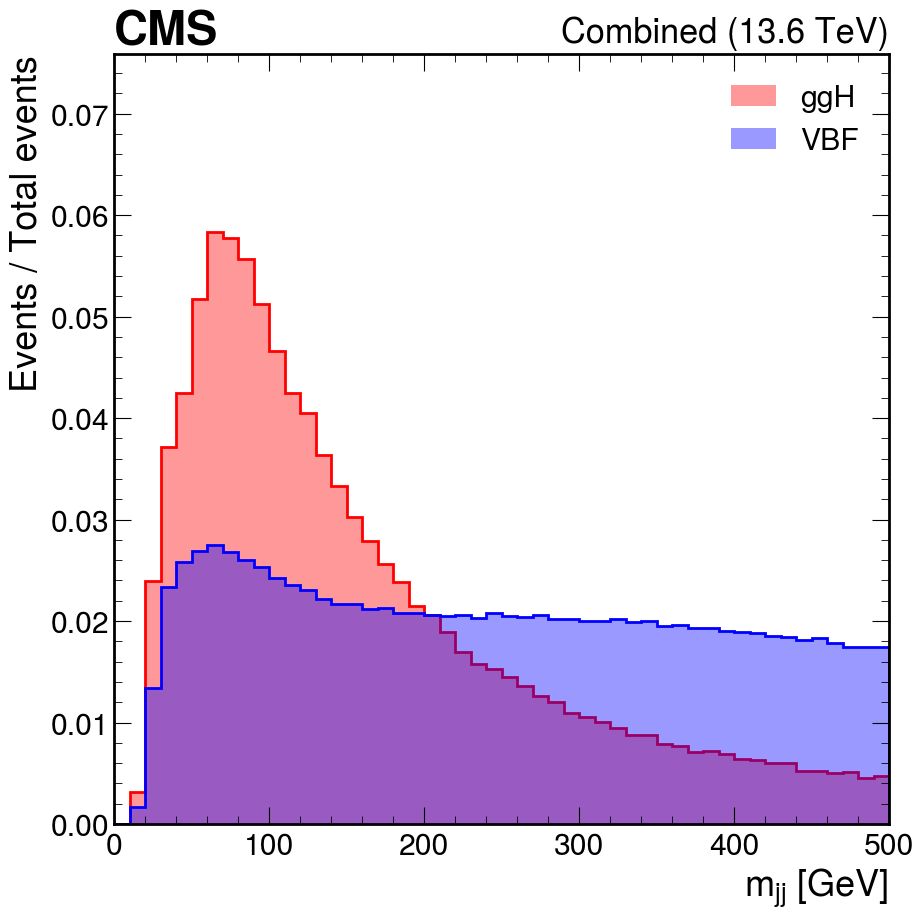

../../plots/xgboost/categorization/1jet/pt_balance_ggH_vs_VBF Has been created


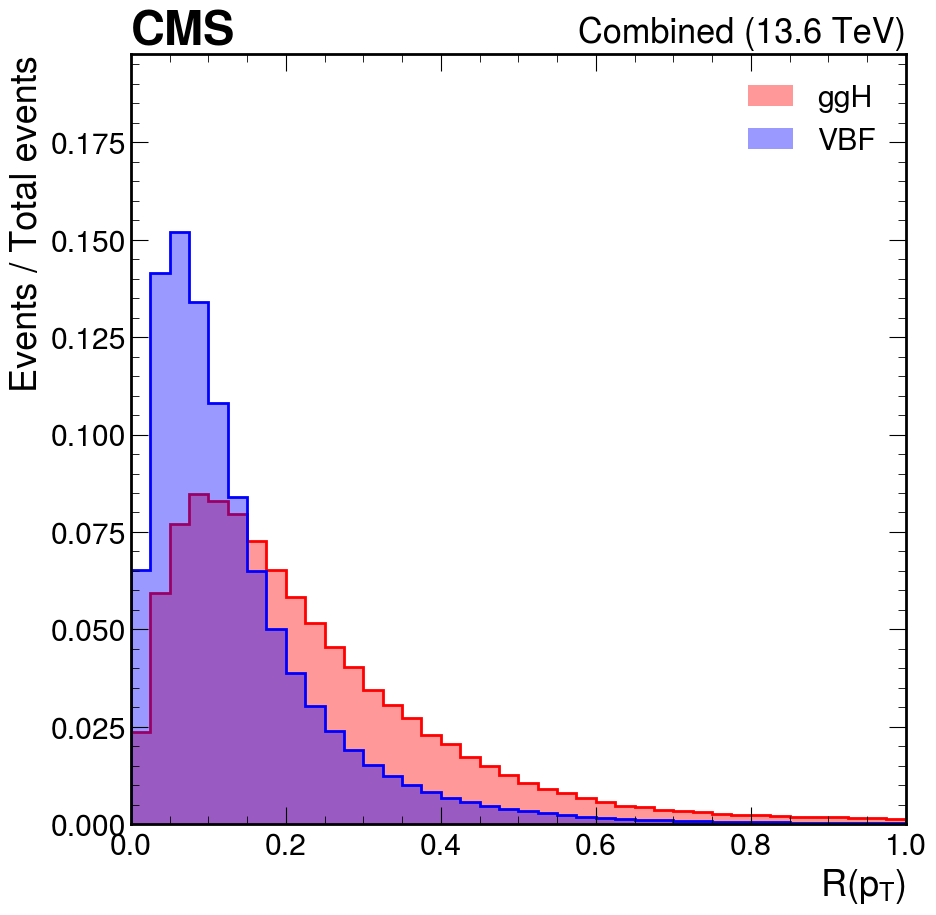

../../plots/xgboost/categorization/1jet/pt_centrality_ggH_vs_VBF Has been created


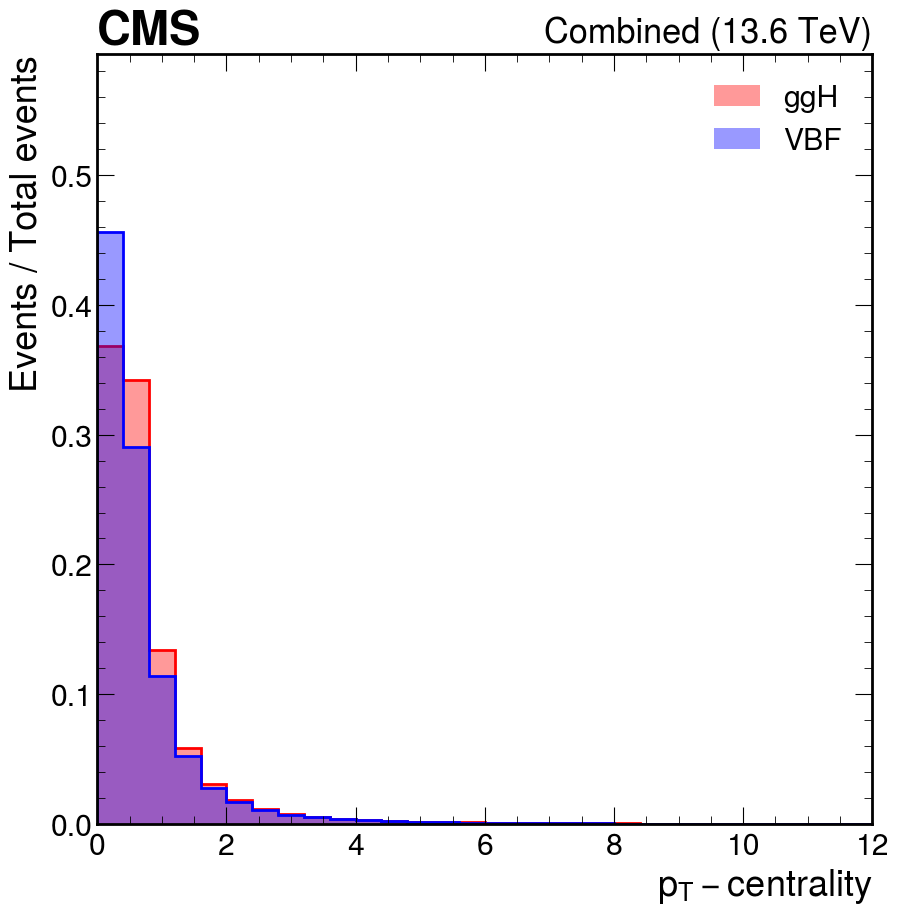

../../plots/xgboost/categorization/1jet/leading_jet_eta_ggH_vs_VBF Has been created


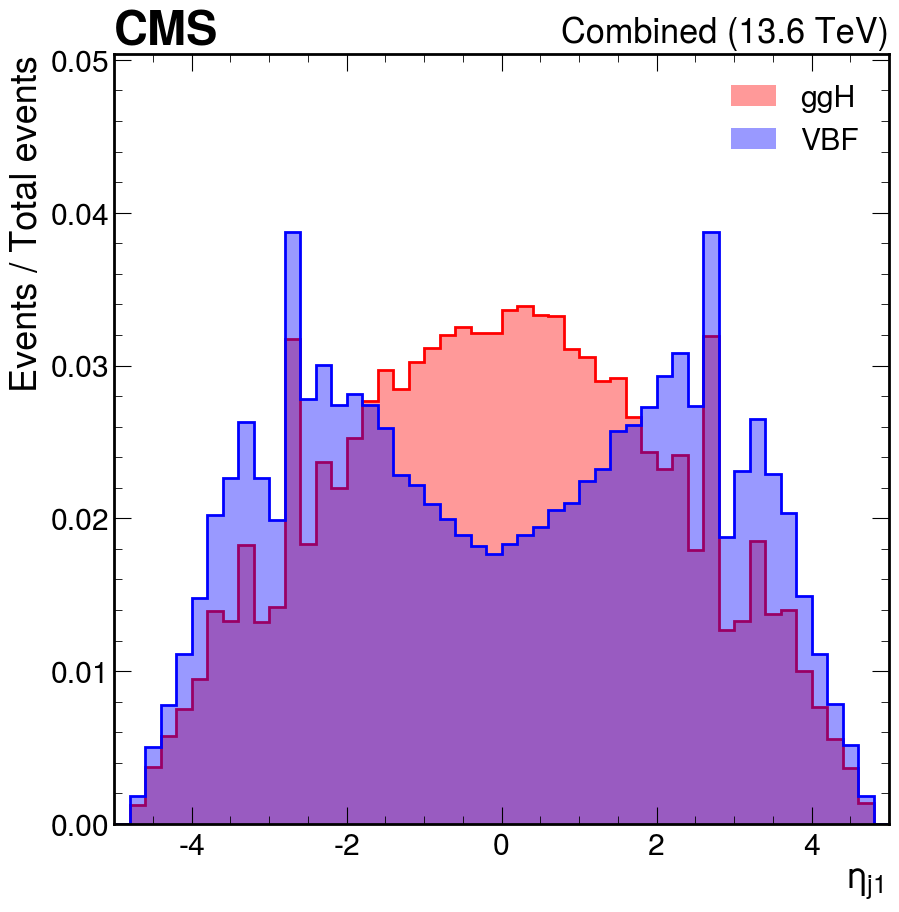

../../plots/xgboost/categorization/1jet/subleading_jet_eta_ggH_vs_VBF Has been created


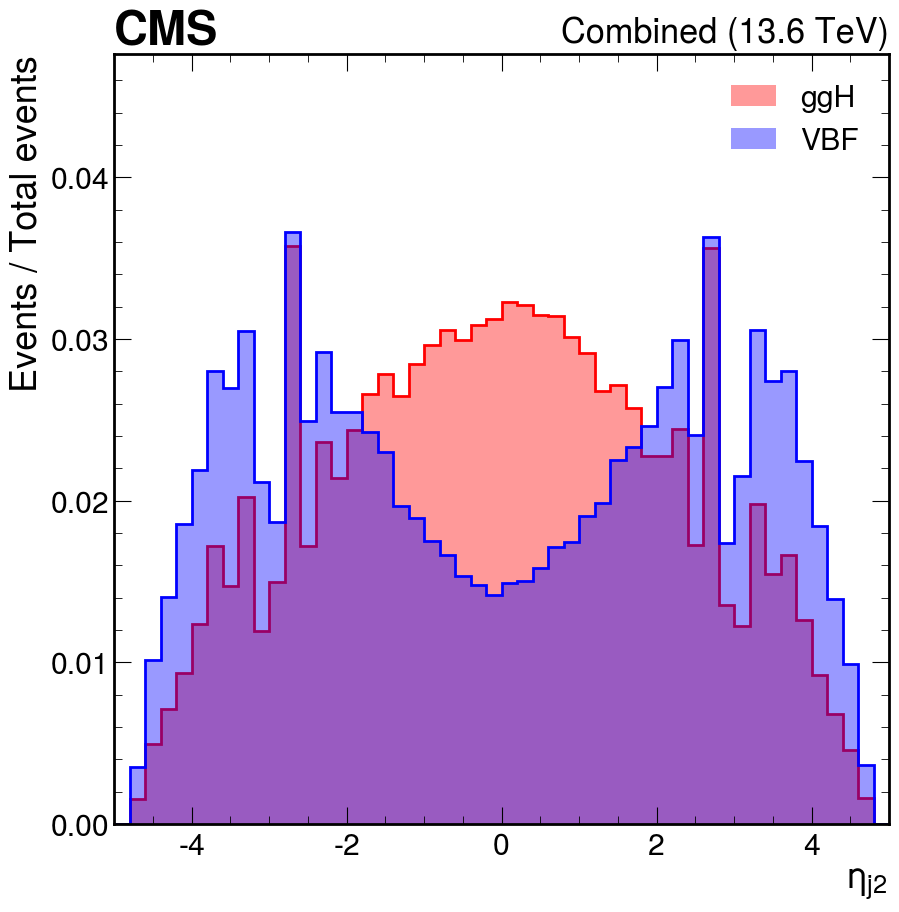

../../plots/xgboost/categorization/1jet/delta_eta_diJet_ggH_vs_VBF Has been created


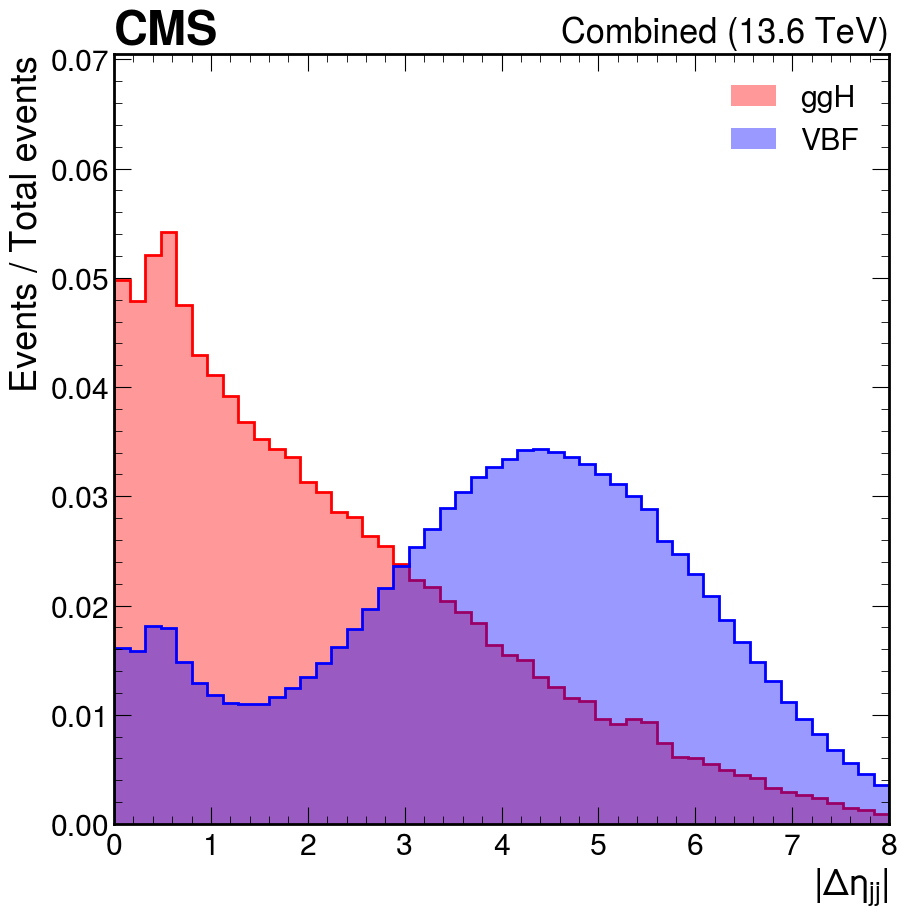

../../plots/xgboost/categorization/1jet/delta_phi_diJet_ggH_vs_VBF Has been created


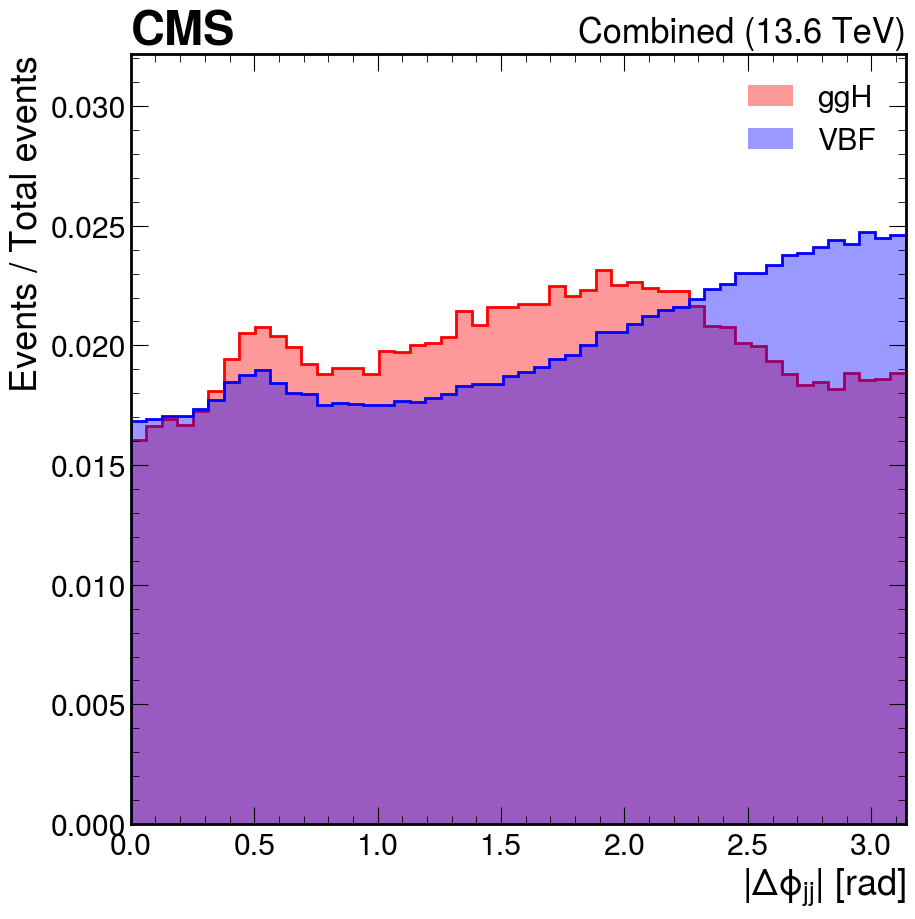

../../plots/xgboost/categorization/1jet/n_jet_ggH_vs_VBF Has been created


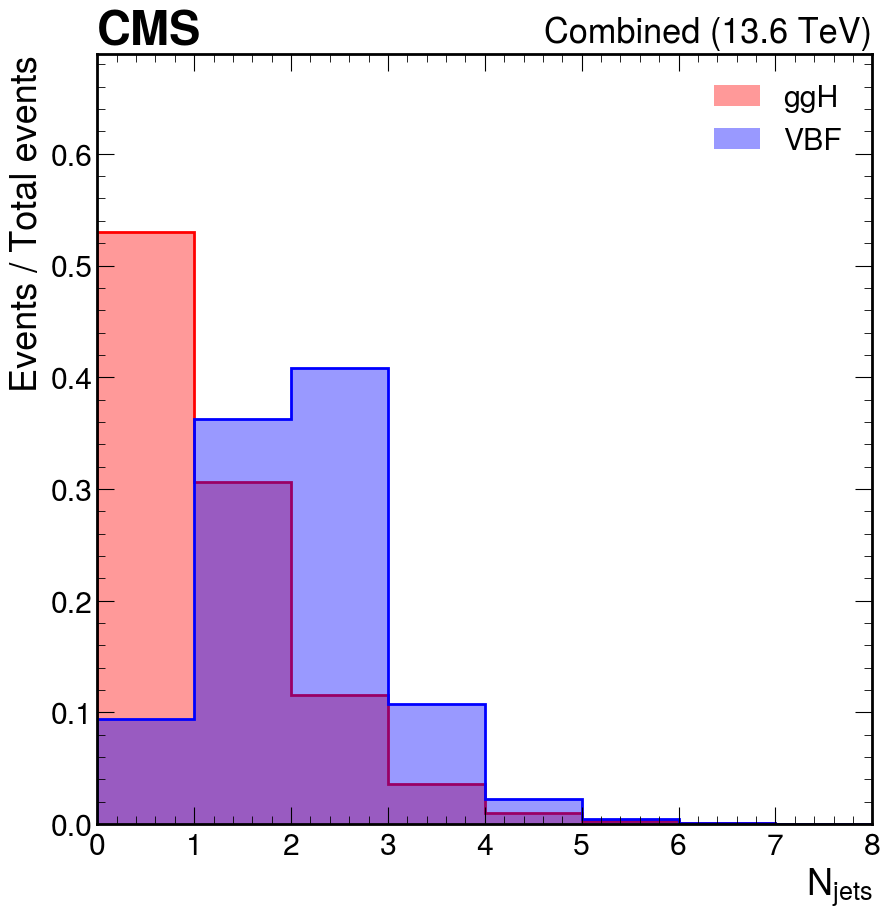

../../plots/xgboost/categorization/1jet/leading_jet_pt_ggH_vs_VBF Has been created


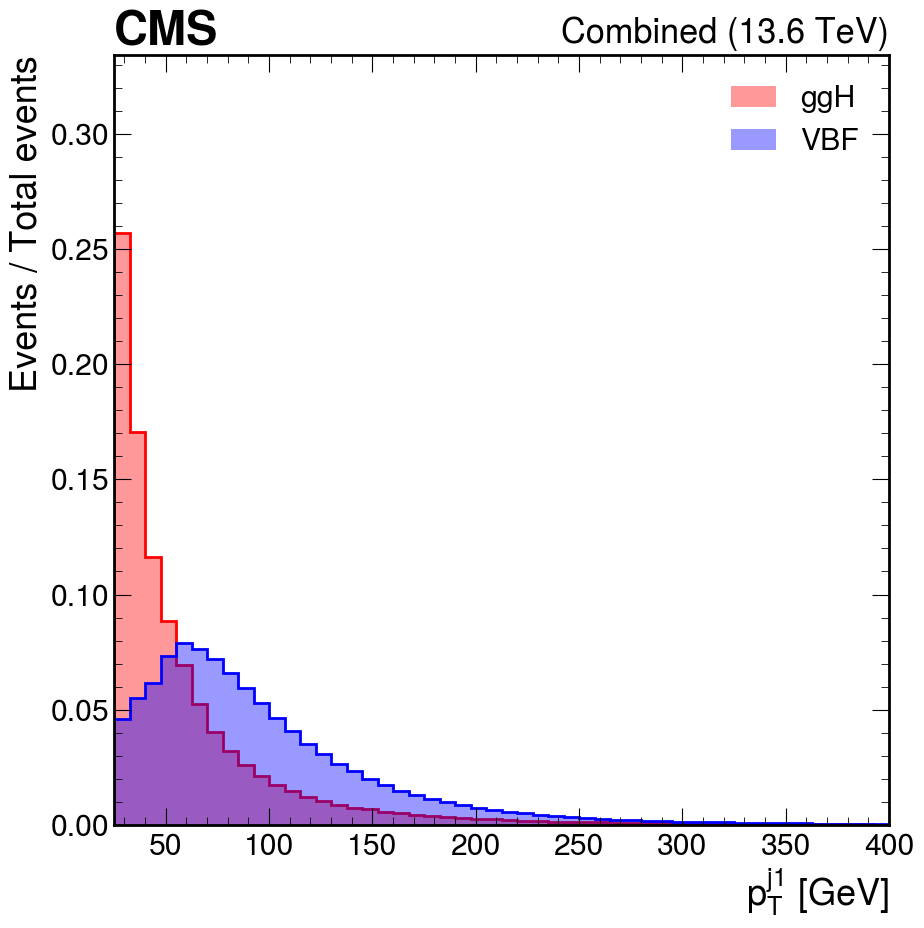

../../plots/xgboost/categorization/1jet/subleading_jet_pt_ggH_vs_VBF Has been created


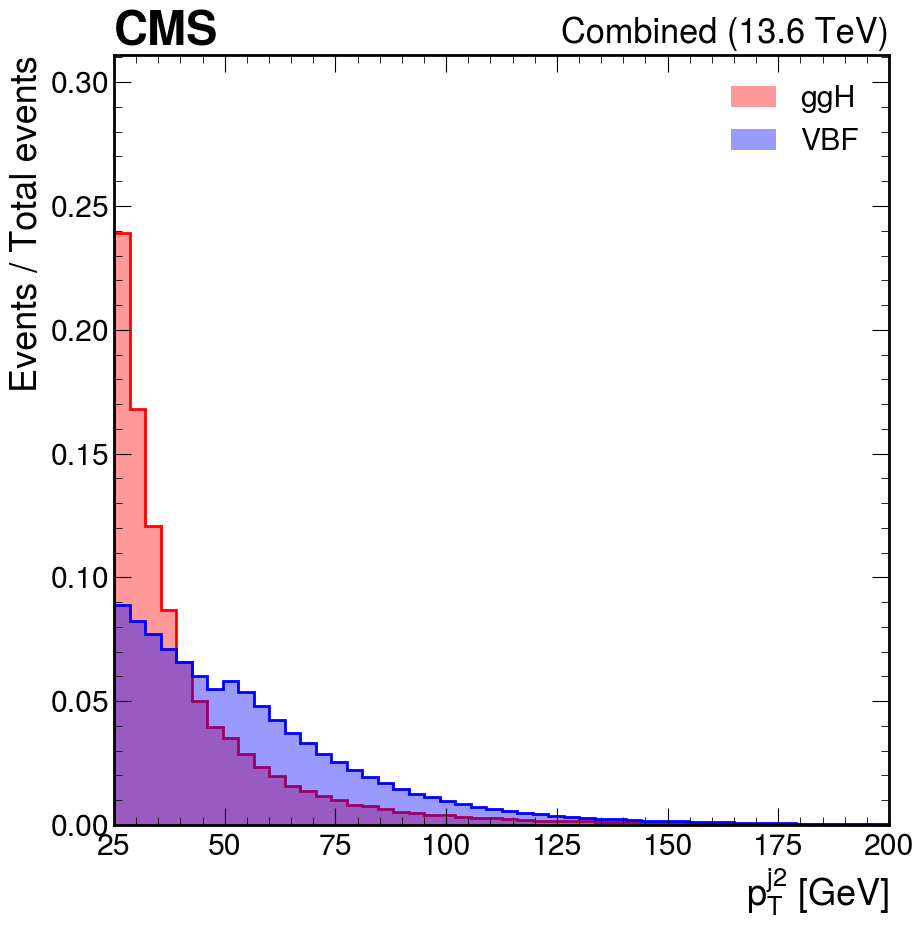

../../plots/xgboost/categorization/1jet/min_delta_eta_diMuon_jet_ggH_vs_VBF Has been created


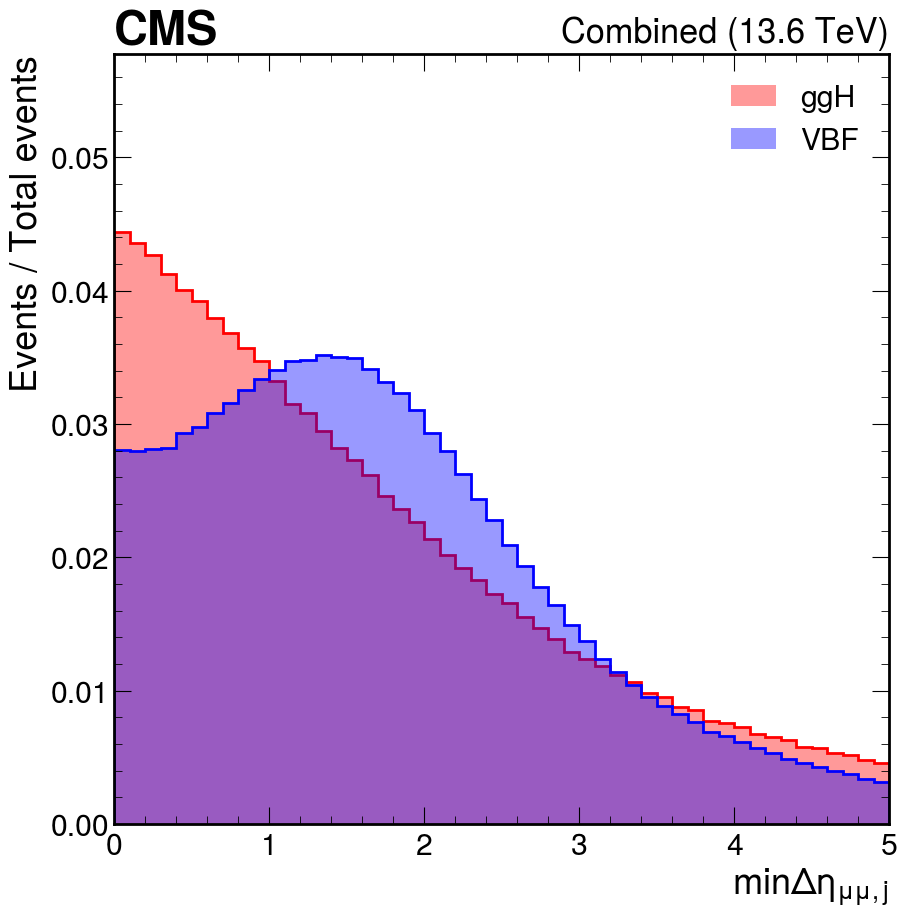

../../plots/xgboost/categorization/1jet/min_delta_phi_diMuon_jet_ggH_vs_VBF Has been created


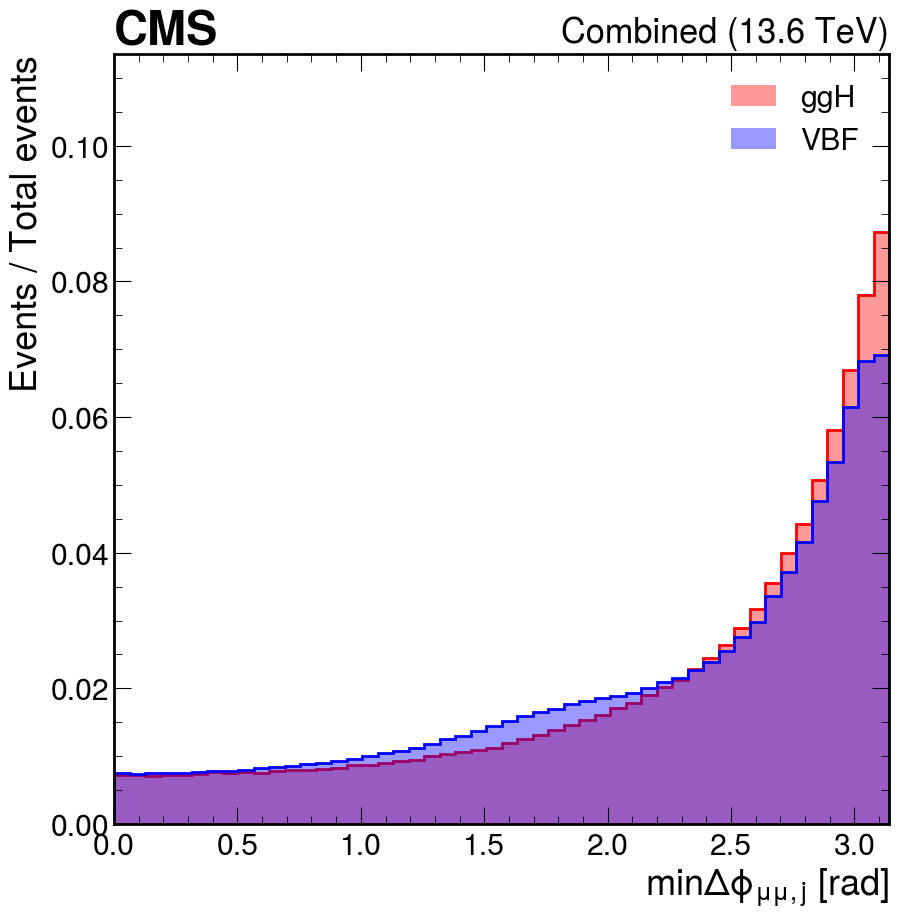

../../plots/xgboost/categorization/1jet/diMuon_bsConstrainedPt_ggH_vs_VBF Has been created


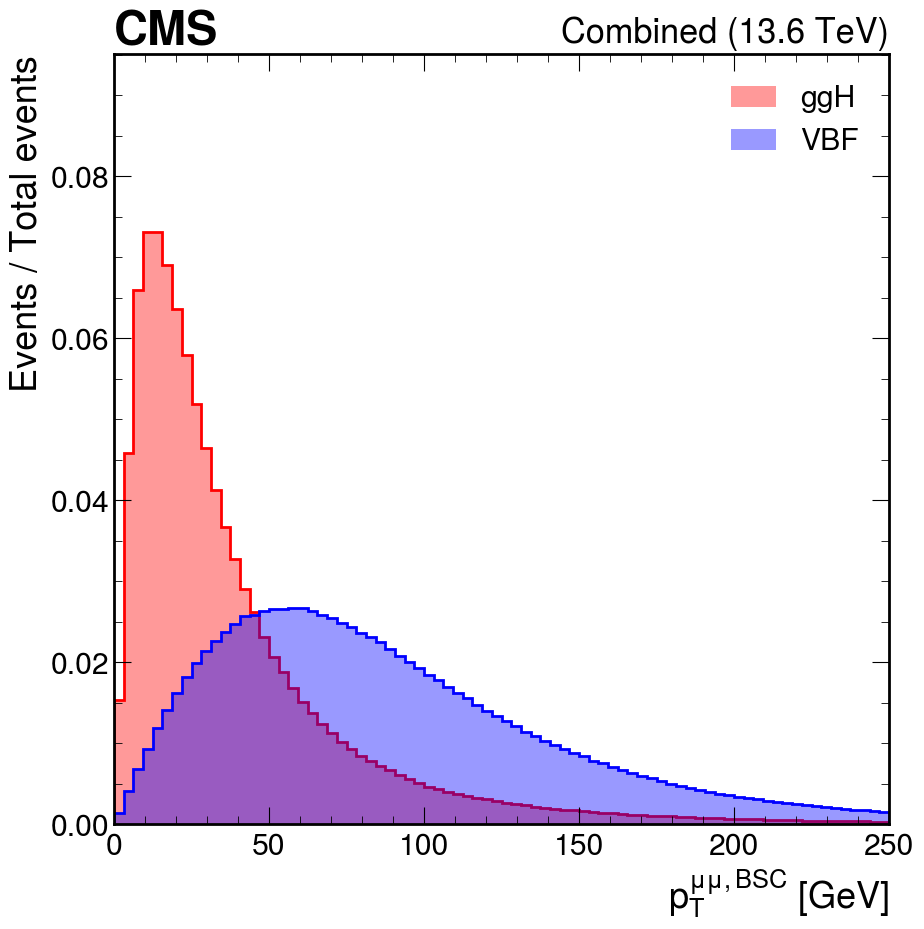

../../plots/xgboost/categorization/1jet/diMuon_rapidity_ggH_vs_VBF Has been created


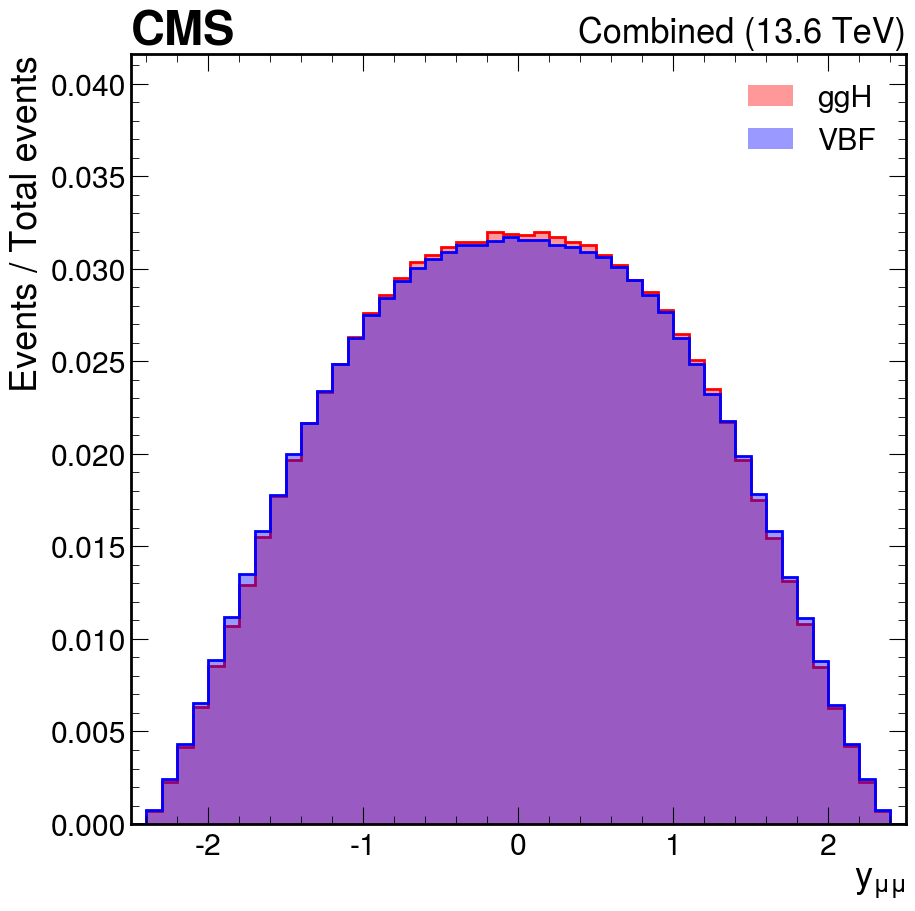

../../plots/xgboost/categorization/1jet/HT_ggH_vs_VBF Has been created


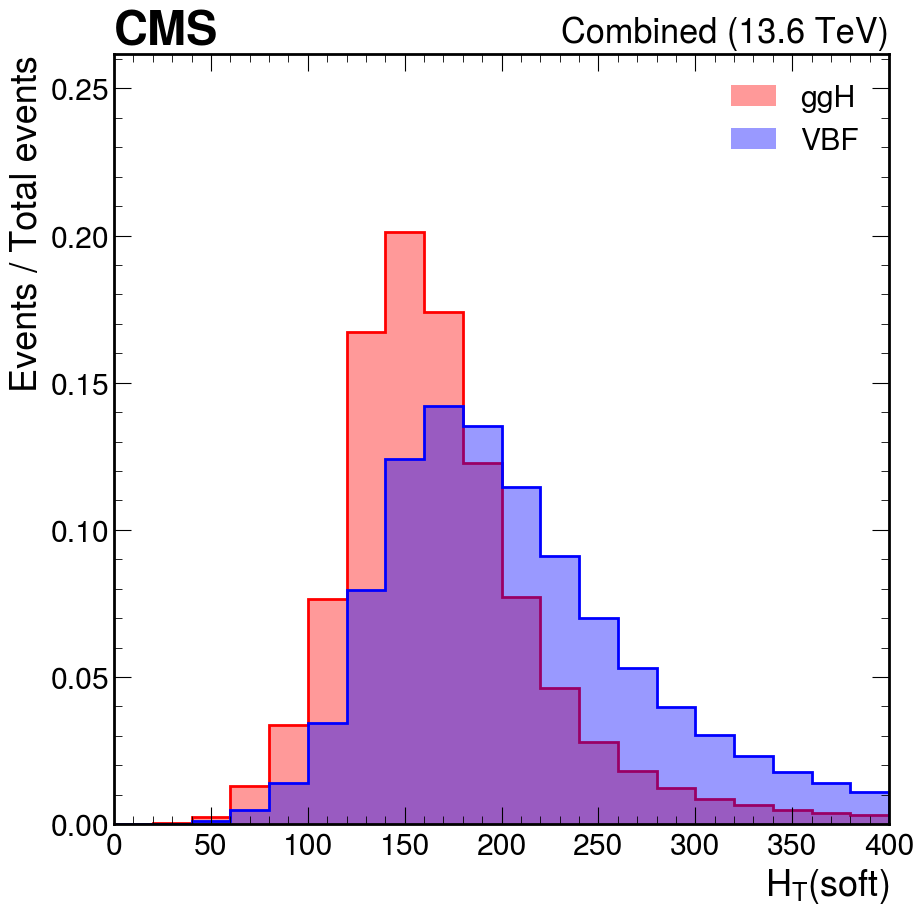

../../plots/xgboost/categorization/1jet/HT_pt2_ggH_vs_VBF Has been created


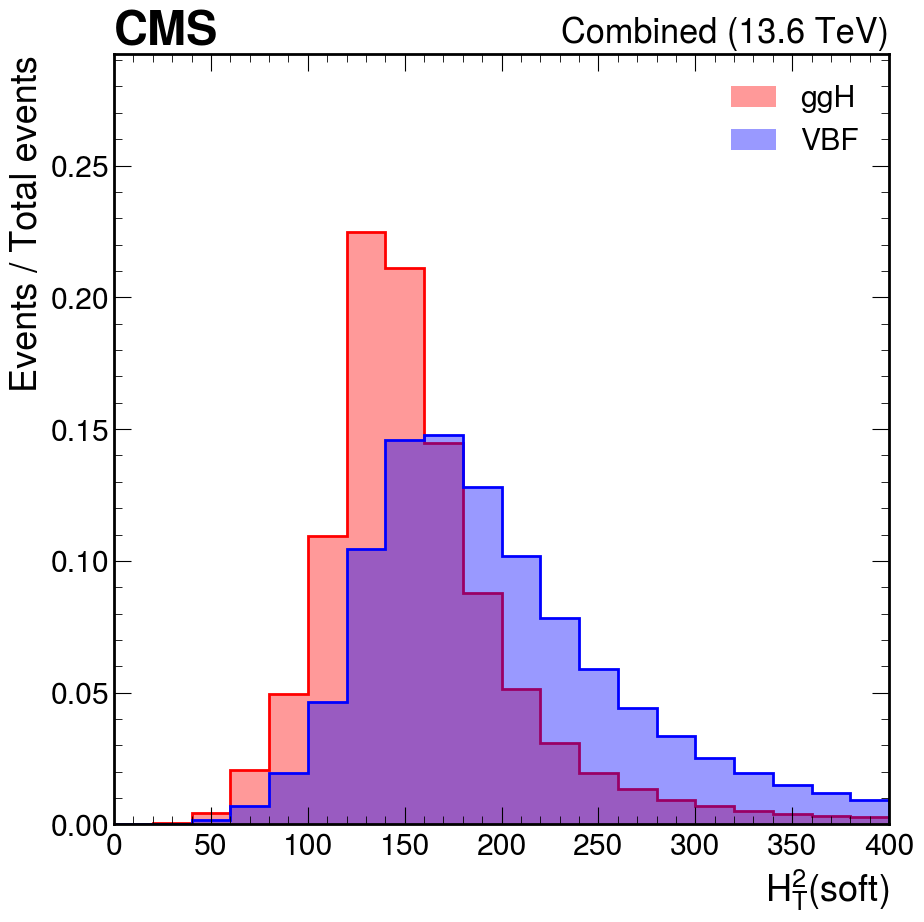

../../plots/xgboost/categorization/1jet/HT_pt5_ggH_vs_VBF Has been created


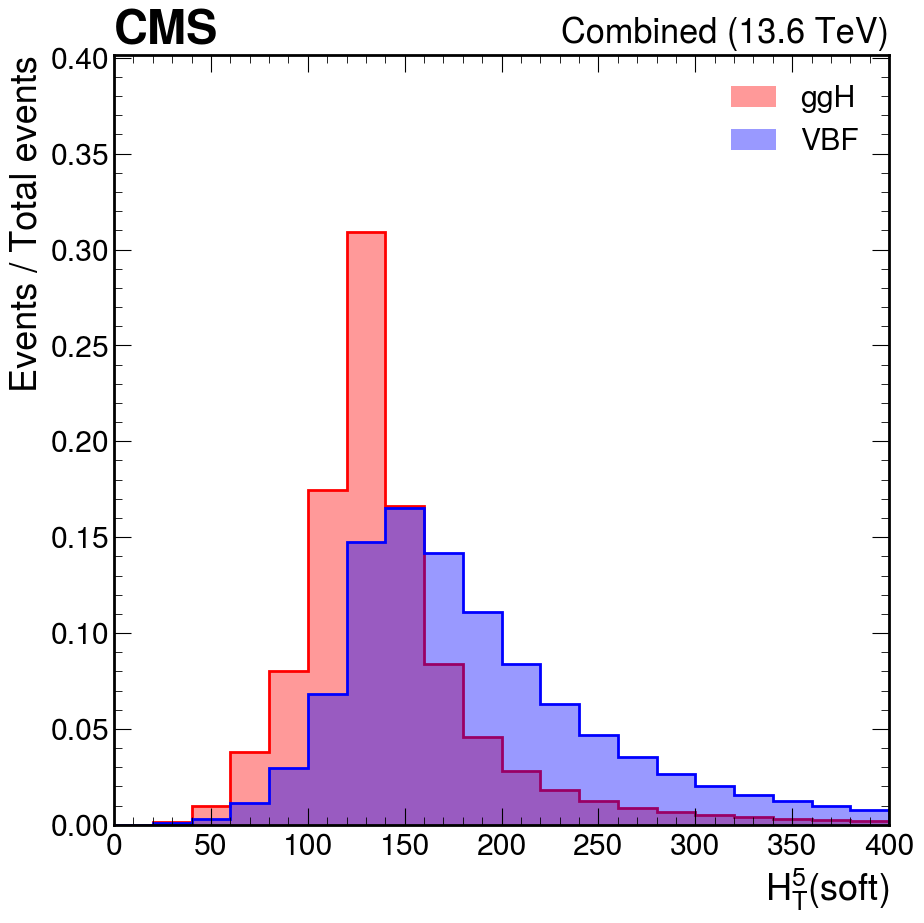

../../plots/xgboost/categorization/1jet/HT_pt10_ggH_vs_VBF Has been created


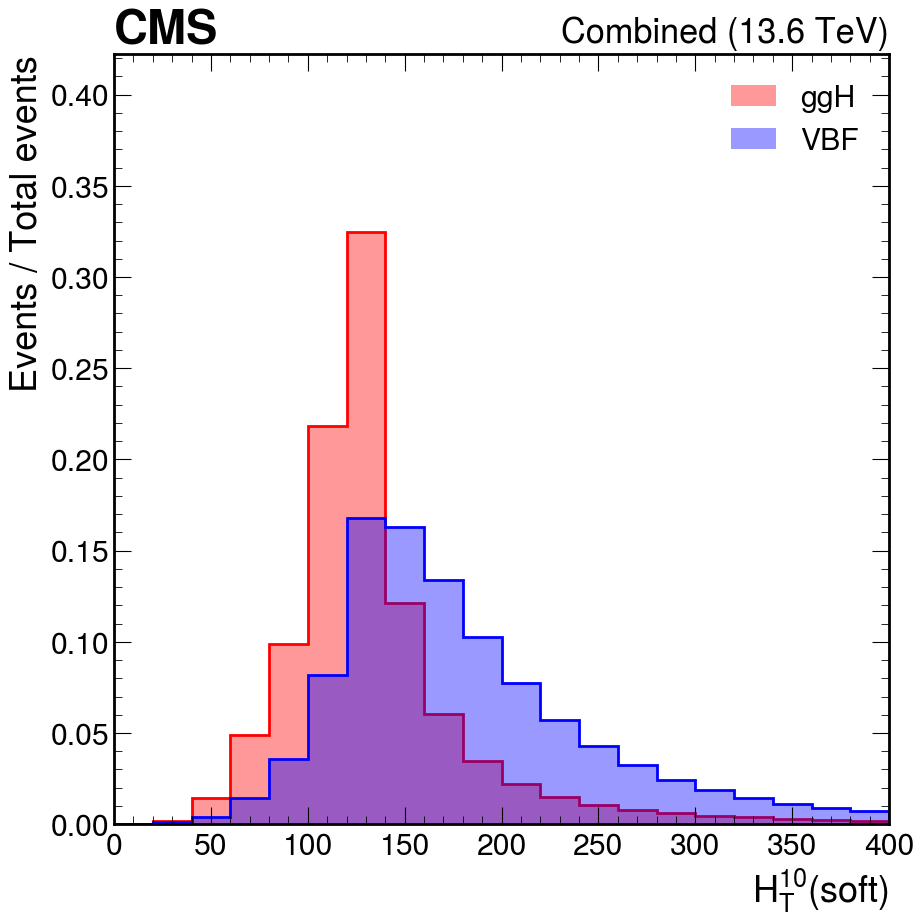

../../plots/xgboost/categorization/1jet/z_zeppenfeld_ggH_vs_VBF Has been created


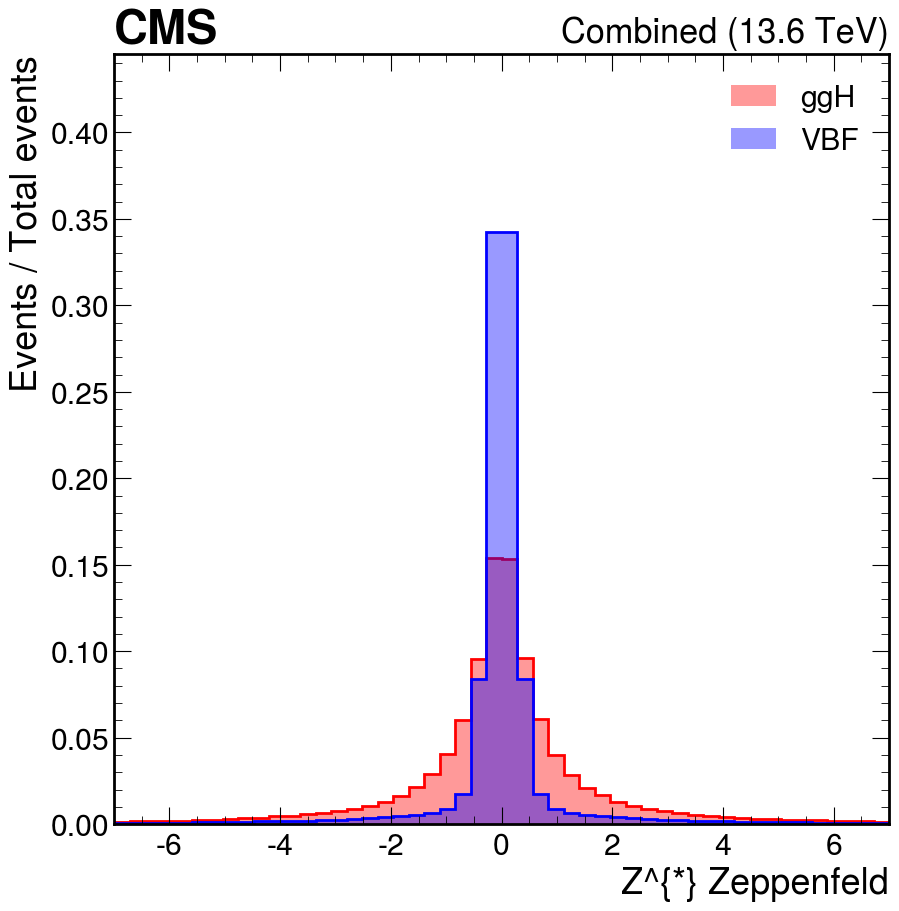

In [26]:
sys.path.insert(0, os.path.abspath("../../plot_macros"))
from utils.ggH_vs_VBF import draw_ggH_vs_VBF_comparison

for variable in bdt_variables[:-3]:
    draw_ggH_vs_VBF_comparison(bdt_df, variable, output_directory=plot_path + "1jet/")

In [16]:
isggH = bdt_df["is_ggH_category"]
isVBF = bdt_df["is_VBF_category"]

In [17]:
orthogonal = (isggH + isVBF) == 1
len(orthogonal[orthogonal == False])

0

In [18]:
y_pred_kinematic = 1 - bdt_df["is_ggH_category"]

In [19]:
y_pred_kinematic

0          0
1          0
2          0
3          0
4          0
          ..
8122536    1
8122537    1
8122538    1
8122539    0
8122540    0
Name: is_ggH_category, Length: 8122536, dtype: uint32

In [20]:
Y

0          0
1          0
2          0
3          0
4          0
          ..
8122536    1
8122537    1
8122538    1
8122539    1
8122540    1
Name: y_truth, Length: 8122536, dtype: int64

In [21]:
X

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet,diMuon_bsConstrainedPt,diMuon_rapidity,HT,HT_pt2,HT_pt5,HT_pt10,z_zeppenfeld
0,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.000000,0.000000,0.000000,14.042969,0.524170,193.875000,177.09375,140.000000,132.062500,0.000000
1,0.000000,-1.000000,-1.000000,-0.860229,0.000000,0.000000,-1.000000,1,37.898438,0.000000,3.309082,3.111816,43.546875,1.427490,181.656250,174.50000,156.906250,149.750000,0.000000
2,62.906250,0.317627,0.768677,-0.946167,-2.197754,1.251709,1.260742,2,40.039062,29.316406,2.498047,1.680176,60.203125,0.877441,170.875000,160.53125,129.625000,121.625000,1.965820
3,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.000000,0.000000,0.000000,24.191406,-1.793945,132.031250,127.93750,127.937500,127.937500,0.000000
4,99.546875,0.281677,-0.113708,0.875488,-0.904175,1.779785,-2.291992,2,40.367188,32.382812,2.287598,1.651855,8.138672,-0.729858,197.750000,178.87500,161.093750,148.250000,-0.408936
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8122536,1529.000000,0.030697,0.286194,-2.205566,4.110352,6.316406,-2.828613,2,105.375000,39.937500,2.991211,0.471924,75.078125,0.463013,188.937500,173.87500,127.953125,127.953125,-0.078461
8122537,742.375000,0.074295,1.084229,-1.927734,2.539062,4.466797,1.061035,2,85.062500,75.203125,1.554932,2.570312,159.125000,-0.294861,238.625000,231.37500,221.406250,221.406250,-0.135223
8122538,1241.250000,0.033943,2.008789,-1.686279,4.093750,5.780273,0.408325,3,83.546875,57.257812,2.406738,2.912598,141.656250,1.432373,262.625000,252.25000,226.500000,226.500000,0.039612
8122539,569.125000,0.096817,0.062027,-0.529663,1.427246,1.957031,-3.107910,2,272.437500,128.687500,0.118820,0.191101,97.984375,1.132324,329.625000,320.56250,318.437500,318.437500,0.351318


In [ ]:
scaler = StandardScaler()
scaler.set_output(transform='pandas')

X = scaler.fit_transform(X)

In [22]:
X

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet,diMuon_bsConstrainedPt,diMuon_rapidity,HT,HT_pt2,HT_pt5,HT_pt10,z_zeppenfeld
0,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.000000,0.000000,0.000000,14.042969,0.524170,193.875000,177.09375,140.000000,132.062500,0.000000
1,0.000000,-1.000000,-1.000000,-0.860229,0.000000,0.000000,-1.000000,1,37.898438,0.000000,3.309082,3.111816,43.546875,1.427490,181.656250,174.50000,156.906250,149.750000,0.000000
2,62.906250,0.317627,0.768677,-0.946167,-2.197754,1.251709,1.260742,2,40.039062,29.316406,2.498047,1.680176,60.203125,0.877441,170.875000,160.53125,129.625000,121.625000,1.965820
3,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.000000,0.000000,0.000000,24.191406,-1.793945,132.031250,127.93750,127.937500,127.937500,0.000000
4,99.546875,0.281677,-0.113708,0.875488,-0.904175,1.779785,-2.291992,2,40.367188,32.382812,2.287598,1.651855,8.138672,-0.729858,197.750000,178.87500,161.093750,148.250000,-0.408936
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8122536,1529.000000,0.030697,0.286194,-2.205566,4.110352,6.316406,-2.828613,2,105.375000,39.937500,2.991211,0.471924,75.078125,0.463013,188.937500,173.87500,127.953125,127.953125,-0.078461
8122537,742.375000,0.074295,1.084229,-1.927734,2.539062,4.466797,1.061035,2,85.062500,75.203125,1.554932,2.570312,159.125000,-0.294861,238.625000,231.37500,221.406250,221.406250,-0.135223
8122538,1241.250000,0.033943,2.008789,-1.686279,4.093750,5.780273,0.408325,3,83.546875,57.257812,2.406738,2.912598,141.656250,1.432373,262.625000,252.25000,226.500000,226.500000,0.039612
8122539,569.125000,0.096817,0.062027,-0.529663,1.427246,1.957031,-3.107910,2,272.437500,128.687500,0.118820,0.191101,97.984375,1.132324,329.625000,320.56250,318.437500,318.437500,0.351318


In [23]:
bdt_df[bdt_df.y_truth == 1].weight.sum()
signal_counts = np.array([bdt_df[bdt_df.y_truth == 0].weight.sum(), bdt_df[bdt_df.y_truth == 1].weight.sum()])

In [25]:
len(bdt_df)

8122536

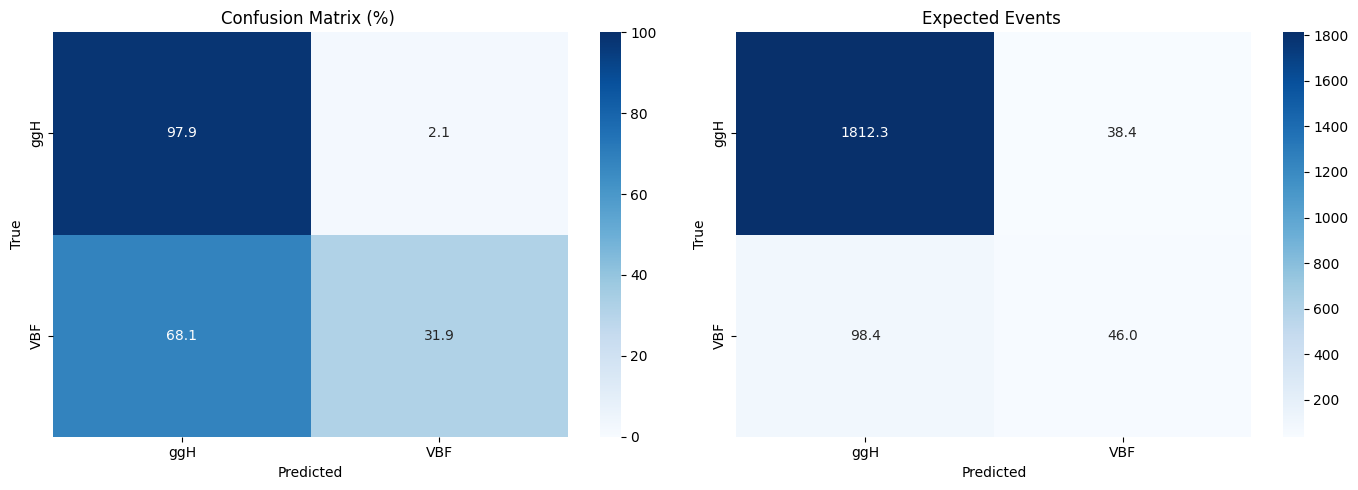

In [24]:
plot_confusion_matrix(Y, y_pred_kinematic, signal_counts)

In [ ]:
bdt_df

In [ ]:
SEED = 7
TEST_SIZE = 0.4
SAMPLE_SIZE = 1.0
x_train, x_test, y_train, y_test, w_train, w_test = train_test_split(
    X.values,
    Y.values,
    bdt_df["weight"].values,
    train_size=SAMPLE_SIZE * (1 - TEST_SIZE),
    test_size=SAMPLE_SIZE * TEST_SIZE,
    random_state=SEED,
)

In [ ]:
X

In [ ]:
x_train

In [ ]:
model = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=2000,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    verbosity=1,
    n_jobs=4,
    eval_metric=["logloss", "auc"],
    device='cuda',
    early_stopping_rounds=50,
)

model.fit(
        x_train,
        y_train,
        eval_set=[(x_train, y_train), (x_test, y_test)],
)

y_score = model.predict_proba(x_test)[:, 1]
y_score_train = model.predict_proba(x_train)[:, 1]
y_pred = np.round(y_score).astype(int)

In [ ]:
y_score[(y_score > 0) & (y_score < 1)]

In [ ]:
plot_confusion_matrix(Y, y_pred_kinematic, signal_counts)

In [ ]:
plot_confusion_matrix(Y, y_pred_kinematic, signal_counts, title="kinematic")
plot_confusion_matrix(y_test, (y_score > 0.89).astype(int), signal_counts, title="BDT > 0.9")

In [ ]:
model.get_booster().feature_names = bdt_variables[:-3]

In [ ]:
xgb.plot_importance(model, xlabel="F score (weight)")

In [ ]:
print(w_train.sum())

In [ ]:
for label, val in [("ggH (truth)", 0), ("VBF (truth)", 1)]:
    plt.hist(
        y_score[y_test == val], bins=50, weights=w_test[y_test == val],
        density=True, histtype="step", lw=2, label=f"{label} - test",
    )
    plt.hist(
        y_score_train[y_train == val], bins=50, weights=w_train[y_train == val],
        density=True, histtype="step", lw=2, linestyle="--", label=f"{label} - train",
    )
plt.xlabel("BDT score (0=ggH-like, 1=VBF-like)")
plt.ylabel("Events (normalized)")
plt.legend()
plt.savefig("score_plot.png")
plt.show()

In [ ]:
fpr, tpr, thr = roc_curve(
        y_test,
        y_score,
        sample_weight=w_test,
    )
#AUC = roc_auc_score(y_test, y_score, sample_weight=w_test)

In [ ]:
f = plt.figure()
# ax = f.add_subplot(111)
lw = 2
plt.plot(fpr, tpr, color="darkorange", lw=lw, label="ROC curve")
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 0.1])
plt.ylim([0.0, 0.65])
plt.ylabel("VBF Efficiency")
plt.xlabel("ggH Mismatch Rate")
# plt.axhline(y=0.9, color="black", linestyle="--")
# plt.axhline(y=0.8, color="black")
# plt.text(0.5,0.1,'WP80: bkg eff = %.4f'%WP80_effBkg, fontsize=12)
# plt.text(0.5,0.2,'WP90: bkg eff = %.4f'%WP90_effBkg, fontsize=12)
# plt.text(0.5,0.3,'WP90: S/sqrt(B) = %.2f'%WP90_significance, fontsize=12)
# plt.text(0.5, 0.3, "AUC = %.4f" % AUC, hhhontsize=12)
#plt.text(0.5, 0.3, "AUC = %.4f" % AUC)
# plt.title('Receiver operating characteristic example')
# plt.legend(loc="lower right")

plt.scatter(
    0.023, 0.428,
    color="red",
    s=80,
    marker="o",
    zorder=5,
    label="Equivalent BDT Point"
)

plt.scatter(
    0.021, 0.319,
    color="black",
    s=80,
    marker="o",
    zorder=5,
    label="Kinematic Point"
)

hep.cms.label(
    data="True",
    label="",
    year="Combined",
    com="13.6",
)
plt.legend()
#plt.savefig(f"{plot_path}training/myroc_{test_name}.pdf")
#plt.savefig(f"{plot_path}training/myroc_{test_name}.png")